# Osaka Bay Hypoxic Zone Area and Benthos Biodiversity Analysis

This notebook examines the spatial and temporal relationship between the area of hypoxic zones and benthic macrofauna biodiversity/abundance in Osaka Bay using three integrated datasets:
1. **Merged Water Quality GDF (`merged_gdf.feather`):** Multi-decadal (1981–2024) seasonal data at 10 fixed stations containing clean, float64 V2 parameters (DO, salinity, temperature, nutrients, density, and stratification). Used for bottom DO mapping.
2. **Targeted Biological Survey (`検索結果＿大阪湾＿生物.csv`):** Seasonal (1982–1983) benthic species counts, abundance, biomass, and dominant species lists.
3. **SIS Water Mass boundary (`sea_area_mask_simplified.shp`):** Spatial boundary polygon used for water-masking the grid.

Instead of using a simple temperature stratification proxy, we map **actual hypoxic zones ($DO \le 2\text{ mg/L}$)** directly using a physics-based steady-state diffusion interpolation method (Successive Over-Relaxation solver) on a 1000m grid.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist, squareform
from sklearn.manifold import MDS
from shapely.geometry import box, Point
from shapely.prepared import prep
from pyproj import Transformer
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon
import scipy.ndimage as ndimage
from pathlib import Path

# Resolve project root path and append to sys.path
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

# Apply global style settings
plt.style.use(str(project_root / 'project_style.mplstyle'))
print("Global setup completed successfully.")


Global setup completed successfully.


## 2. Data Ingestion and Cleaning
We load biological data from `検索結果＿大阪湾＿生物.csv` and water quality data from the processed `merged_gdf.feather`.


In [2]:
bio_path = ProjectPaths.DATA_DIR / 'raw' / 'Osaka Bay' / '検索結果＿大阪湾＿生物.csv'

# Load and clean Biological CSV
df_bio = pd.read_csv(bio_path, encoding='cp932')
df_bio.columns = df_bio.columns.str.strip().str.replace(r'\s+', '', regex=True)

# Load Merged Water Quality GDF and filter to Osaka Bay
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
osaka_wq = merged_gdf[merged_gdf['division'] == 'Osaka Bay'].copy()

print(f"Biological CSV shape: {df_bio.shape}")
print(f"Osaka Bay Water Quality GDF shape: {osaka_wq.shape}")


Biological CSV shape: (180, 24)
Osaka Bay Water Quality GDF shape: (3440, 68)


## 3. Physics-Based DO Diffusion Interpolation
We set up a 1000m calculation grid in UTM Zone 53N (`EPSG:32653`), clip the water boundary to Osaka Bay, build a water mask, and implement the Successive Over-Relaxation (SOR) steady-state diffusion solver to interpolate bottom DO ($DO$ at $saisuipoin == 2$) for each available summer season.


In [3]:
# 1. Setup boundary and UTM grid
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_simplified.shp'
sis_water_boundary = gpd.read_file(water_boundary_path)
if sis_water_boundary.crs != 'EPSG:4326':
    sis_water_boundary = sis_water_boundary.to_crs('EPSG:4326')

# Bounding box of Osaka Bay
osaka_bbox = box(134.8, 34.15, 135.6, 34.85)
osaka_bbox_gdf = gpd.GeoDataFrame(geometry=[osaka_bbox], crs='EPSG:4326')
osaka_water = gpd.clip(sis_water_boundary, osaka_bbox_gdf)

# Project boundary to UTM Zone 53N
utm_crs = 'EPSG:32653'
osaka_water_utm = osaka_water.to_crs(utm_crs)
bounds_utm = osaka_water_utm.total_bounds

# Create grid (1000m resolution)
GRID_RES = 1000  # meters
grid_x_1d = np.arange(bounds_utm[0], bounds_utm[2], GRID_RES)
grid_y_1d = np.arange(bounds_utm[1], bounds_utm[3], GRID_RES)
grid_x, grid_y = np.meshgrid(grid_x_1d, grid_y_1d)

# Vectorized water mask
water_polygon = osaka_water_utm.geometry.union_all()
prepared_poly = prep(water_polygon)
flat_x = grid_x.flatten()
flat_y = grid_y.flatten()
grid_points = [Point(x, y) for x, y in zip(flat_x, flat_y)]
valid_points_mask = np.array([prepared_poly.contains(pt) for pt in grid_points])
water_mask = valid_points_mask.reshape(grid_x.shape)

# Coordinate re-projection back to WGS84 for plotting
transformer = Transformer.from_crs(utm_crs, 'EPSG:4326', always_xy=True)
lon_flat, lat_flat = transformer.transform(flat_x, flat_y)
lon_wgs = lon_flat.reshape(grid_x.shape)
lat_wgs = lat_flat.reshape(grid_y.shape)

print(f"Grid shape: {grid_x.shape} ({grid_x.size} points)")
print(f"Water cells: {water_mask.sum()} / {water_mask.size}")

# Pre-compute SOR matrices
kernel = np.array([[0, 1, 0],
                   [1, 0, 1],
                   [0, 1, 0]])
water_float = water_mask.astype(np.float64)
W = ndimage.convolve(water_float, kernel, mode='constant', cval=0.0)
valid_W_mask = W > 0
i_indices, j_indices = np.indices(grid_x.shape)
red_mask = (i_indices + j_indices) % 2 == 0
black_mask = ~red_mask

# Build KDTree for station snapping
water_iy, water_ix = np.where(water_mask)
water_coords = np.column_stack([grid_x[water_iy, water_ix],
                                 grid_y[water_iy, water_ix]])
water_tree = cKDTree(water_coords)

# Align fixed stations with UTM
stations_gdf = osaka_wq[['zettaicode', 'longitude', 'latitude']].drop_duplicates().set_index('zettaicode')
stations_utm = gpd.GeoDataFrame(
    stations_gdf,
    geometry=[Point(xy) for xy in zip(stations_gdf.longitude, stations_gdf.latitude)],
    crs='EPSG:4326'
).to_crs(utm_crs)

# SOR solver
def run_diffusion_interpolation(year_data, stations_utm_local, water_mask, grid_x, grid_y, water_tree, water_iy, water_ix, max_iters=500, tol=1e-3, omega=1.8):
    Z = np.full(water_mask.shape, np.nan)
    mean_val = year_data['do_'].mean()
    Z[water_mask] = mean_val
    fixed_mask = np.zeros_like(water_mask, dtype=bool)

    common_ids = year_data.index.intersection(stations_utm_local.index)
    if len(common_ids) == 0:
        return Z

    pts_x = stations_utm_local.loc[common_ids].geometry.x.values
    pts_y = stations_utm_local.loc[common_ids].geometry.y.values
    do_vals = year_data.loc[common_ids, 'do_'].values

    station_coords = np.column_stack([pts_x, pts_y])
    _, nearest_idx = water_tree.query(station_coords)

    for k in range(len(common_ids)):
        iy = water_iy[nearest_idx[k]]
        ix = water_ix[nearest_idx[k]]
        Z[iy, ix] = do_vals[k]
        fixed_mask[iy, ix] = True

    Z_water = np.zeros_like(Z)

    for it in range(max_iters):
        Z_old_water = Z[water_mask].copy()

        with np.errstate(divide='ignore', invalid='ignore'):
            # Red update
            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            update_red = red_mask & water_mask & (~fixed_mask)
            Z[update_red] = (1 - omega) * Z[update_red] + omega * Z_avg[update_red]

            # Black update
            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            update_black = black_mask & water_mask & (~fixed_mask)
            Z[update_black] = (1 - omega) * Z[update_black] + omega * Z_avg[update_black]

        max_diff = np.max(np.abs(Z[water_mask] - Z_old_water))
        if max_diff < tol:
            break

    return Z


ERROR 1: PROJ: proj_create_from_database: Open of /home/reyha/miniconda3/envs/sis_analysis/share/proj failed


Grid shape: (65, 62) (4030 points)
Water cells: 2076 / 4030


In [4]:
summer_wq = osaka_wq[(osaka_wq['season'] == 'Summer') & (osaka_wq['saisuipoin'] == 2)]
available_years = sorted(summer_wq['surveyyear'].unique())

hypoxic_areas = {}
all_Z = {}
cell_area_km2 = (GRID_RES / 1000.0) ** 2  # 1.0 km2 for 1000m resolution

for y in available_years:
    df_y = summer_wq[summer_wq['surveyyear'] == y].set_index('zettaicode')
    do_values = df_y[['do_']].dropna()
    if len(do_values) > 0:
        Z = run_diffusion_interpolation(
            do_values, stations_utm, water_mask, grid_x, grid_y,
            water_tree, water_iy, water_ix
        )
        all_Z[y] = Z
        # Hypoxia is defined as DO <= 2.0 mg/L
        hyp_cells = np.sum((Z <= 2.0) & water_mask)
        hypoxic_areas[y] = hyp_cells * cell_area_km2
    else:
        hypoxic_areas[y] = 0.0

df_hyp_areas = pd.DataFrame(list(hypoxic_areas.items()), columns=['Year', 'Hypoxic_Area_km2'])
print("Estimated Summer Hypoxic Area sizes (km2) over time:")
display(df_hyp_areas.head(10))


Estimated Summer Hypoxic Area sizes (km2) over time:


,Year,Hypoxic_Area_km2
0,1981,0.0
1,1982,6.0
2,1983,16.0
3,1984,20.0
4,1985,15.0
5,1986,0.0
6,1987,15.0
7,1988,27.0
8,1989,5.0
9,1990,25.0


## 4. Benthic Macrofauna Metric Calculation
We parse biological variables from `検索結果＿大阪湾＿生物.csv` and calculate species richness, total abundance, biomass, and Shannon-Wiener index based on dominant species occurrences.


In [5]:
# Clean and prepare biological variables
df_bio['date'] = pd.to_datetime(df_bio['調査年月日'], errors='coerce')
df_bio['Year'] = df_bio['date'].dt.year
df_bio['Month'] = df_bio['date'].dt.month
df_bio['lat_clean'] = pd.to_numeric(df_bio['緯度'], errors='coerce')
df_bio['lon_clean'] = pd.to_numeric(df_bio['経度'], errors='coerce')
df_bio['richness'] = pd.to_numeric(df_bio['種類数'], errors='coerce')
df_bio['total_abundance'] = pd.to_numeric(df_bio['個体数'], errors='coerce')
df_bio['total_biomass'] = pd.to_numeric(df_bio['湿重量'], errors='coerce')
df_bio['sample_id'] = df_bio['date'].astype(str) + '_' + df_bio['地点名称'].astype(str)

# Calculate Shannon index for the top 5 dominant species
def calc_shannon_dom(row):
    counts = []
    num_map = {1: '１', 2: '２', 3: '３', 4: '４', 5: '５'}
    for i in range(1, 6):
        c = pd.to_numeric(row[f'主要種{num_map[i]}個体数'], errors='coerce')
        if not np.isnan(c) and c > 0:
            counts.append(c)
    if not counts:
        return 0.0
    total = sum(counts)
    p = np.array(counts) / total
    return -np.sum(p * np.log(p))

df_bio['shannon_index'] = df_bio.apply(calc_shannon_dom, axis=1)
df_bio = df_bio.dropna(subset=['lat_clean', 'lon_clean', 'richness', 'total_abundance'])

print(f"Processed metrics for {len(df_bio)} biological samples:")
display(df_bio[['調査年月日', '地点名称', 'lat_clean', 'lon_clean', 'richness', 'total_abundance', 'shannon_index']].head())


Processed metrics for 180 biological samples:


,調査年月日,地点名称,lat_clean,lon_clean,richness,total_abundance,shannon_index
0,1982/06/02,39,34.6782,135.2375,15,510,1.064436
1,1982/06/02,15,34.6980,135.3256,7,96,0.997882
2,1982/06/02,1,34.6798,135.4010,35,1767,1.458557
3,1982/06/02,5,34.6633,135.3700,15,283,1.309081
4,1982/06/02,28,34.6622,135.2819,7,19,1.513603


In [6]:
bio_melted = []
num_map = {1: '１', 2: '２', 3: '３', 4: '４', 5: '５'}
for i in range(1, 6):
    cols = ['sample_id', f'主要種{num_map[i]}', f'主要種{num_map[i]}個体数']
    sub = df_bio[cols].copy()
    sub.columns = ['sample_id', 'species', 'abundance']
    bio_melted.append(sub)

df_bio_long = pd.concat(bio_melted, ignore_index=True)
df_bio_long = df_bio_long.dropna(subset=['species'])
df_bio_long['species'] = df_bio_long['species'].astype(str).str.strip()
df_bio_long = df_bio_long[~df_bio_long['species'].isin(['nan', '', 'None'])]
df_bio_long['abundance'] = pd.to_numeric(df_bio_long['abundance'], errors='coerce').fillna(0)

print(f"Total benthic dominant occurrence records: {len(df_bio_long)}")


Total benthic dominant occurrence records: 870


## 5. Calculate Hypoxia Exposure Frequency per Station
We snap each biological station to the nearest water grid cell and calculate its **Hypoxia Exposure Frequency (%)**, which is the percentage of summer years where the interpolated local bottom DO is $\le 2.0\text{ mg/L}$.


In [7]:
bio_geom = [Point(xy) for xy in zip(df_bio['lon_clean'], df_bio['lat_clean'])]
df_bio_gpd = gpd.GeoDataFrame(df_bio, geometry=bio_geom, crs='EPSG:4326').to_crs(utm_crs)

bio_coords = np.column_stack([df_bio_gpd.geometry.x.values, df_bio_gpd.geometry.y.values])
_, bio_nearest_idx = water_tree.query(bio_coords)

exposure_freq = {}
for idx, row in df_bio.iterrows():
    # Find coordinates snapped on grid
    iy = water_iy[bio_nearest_idx[idx]]
    ix = water_ix[bio_nearest_idx[idx]]
    
    # Check values across all summer years
    do_vals = [all_Z[y][iy, ix] for y in available_years if y in all_Z]
    do_vals = [v for v in do_vals if not np.isnan(v)]
    
    if do_vals:
        hyp_count = sum(1 for v in do_vals if v <= 2.0)
        freq = (hyp_count / len(do_vals)) * 100.0
    else:
        freq = 0.0
    
    exposure_freq[row['sample_id']] = freq

df_bio['Hypoxia_Exposure_Freq'] = df_bio['sample_id'].map(exposure_freq)

# Map exposure classes
def get_exposure_class(freq):
    if freq == 0:
        return 'Outside (0%)'
    elif freq <= 50:
        return 'Edge (1-50%)'
    else:
        return 'Inside (>50%)'

df_bio['Exposure_Group'] = df_bio['Hypoxia_Exposure_Freq'].apply(get_exposure_class)
print("Exposure classification summary for benthos stations:")
print(df_bio['Exposure_Group'].value_counts())


Exposure classification summary for benthos stations:
Exposure_Group
Outside (0%)    143
Edge (1-50%)     37
Name: count, dtype: int64


## 6. Integrated Statistical Analysis and Ordination
We compute Spearman correlations, fit a sigmoidal threshold curve, and perform Non-Metric Multidimensional Scaling (NMDS) ordination.


In [8]:
# Spearman correlations
corr_vars = ['richness', 'total_abundance', 'shannon_index', 'Hypoxia_Exposure_Freq']
corr_mat, p_mat = spearmanr(df_bio[corr_vars])
df_corr = pd.DataFrame(corr_mat, columns=corr_vars, index=corr_vars)
print("Spearman Correlation Matrix:")
display(df_corr)

# Sigmoid threshold regression fitting
def sigmoid(x, L, x0, k, b):
    return L / (1 + np.exp(-k * (x - x0))) + b

x_data = df_bio['Hypoxia_Exposure_Freq'].values
y_data = df_bio['shannon_index'].values

try:
    popt, pcov = curve_fit(sigmoid, x_data, y_data, p0=[1.0, 30.0, -0.1, 1.0], maxfev=20000)
    has_fit = True
    print(f"Sigmoid fit parameters: L={popt[0]:.2f}, x0={popt[1]:.2f}, k={popt[2]:.2f}, b={popt[3]:.2f}")
except Exception as e:
    print("Sigmoidal fitting failed, using polynomial fallback:", e)
    has_fit = False


Spearman Correlation Matrix:


,richness,total_abundance,shannon_index,Hypoxia_Exposure_Freq
richness,1.000000,0.626921,0.143934,0.042364
total_abundance,0.626921,1.000000,0.021043,0.341545
shannon_index,0.143934,0.021043,1.000000,0.124187
Hypoxia_Exposure_Freq,0.042364,0.341545,0.124187,1.000000


Sigmoid fit parameters: L=0.72, x0=26.08, k=-3.28, b=0.12


### Non-Metric Multidimensional Scaling (NMDS)
We construct a Bray-Curtis community dissimilarity matrix and project samples to 2D.


In [9]:
# Pivot species abundance matrix (Tidy to Wide)
df_pivot = df_bio_long.pivot_table(index='sample_id', columns='species', values='abundance', aggfunc='sum').fillna(0)
df_pivot = df_pivot[df_pivot.sum(axis=1) > 0]

# Relative abundance standardisation
df_rel = df_pivot.div(df_pivot.sum(axis=1), axis=0)

# Align benthos metadata with pivoted samples
df_bio_aligned = df_bio[df_bio['sample_id'].isin(df_rel.index)].drop_duplicates(subset=['sample_id']).set_index('sample_id')
df_rel_aligned = df_rel.loc[df_bio_aligned.index]

# Bray-Curtis Dissimilarity
bc_dist = squareform(pdist(df_rel_aligned.values, metric='braycurtis'))

# NMDS Projection
mds = MDS(n_components=2, metric=False, dissimilarity='precomputed', random_state=42)
nmds_coords = mds.fit_transform(bc_dist)

df_bio_aligned['NMDS1'] = nmds_coords[:, 0]
df_bio_aligned['NMDS2'] = nmds_coords[:, 1]
print("NMDS community projection completed successfully.")


/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


NMDS community projection completed successfully.


## 7. Generating Visualizations (Figures 1-5)


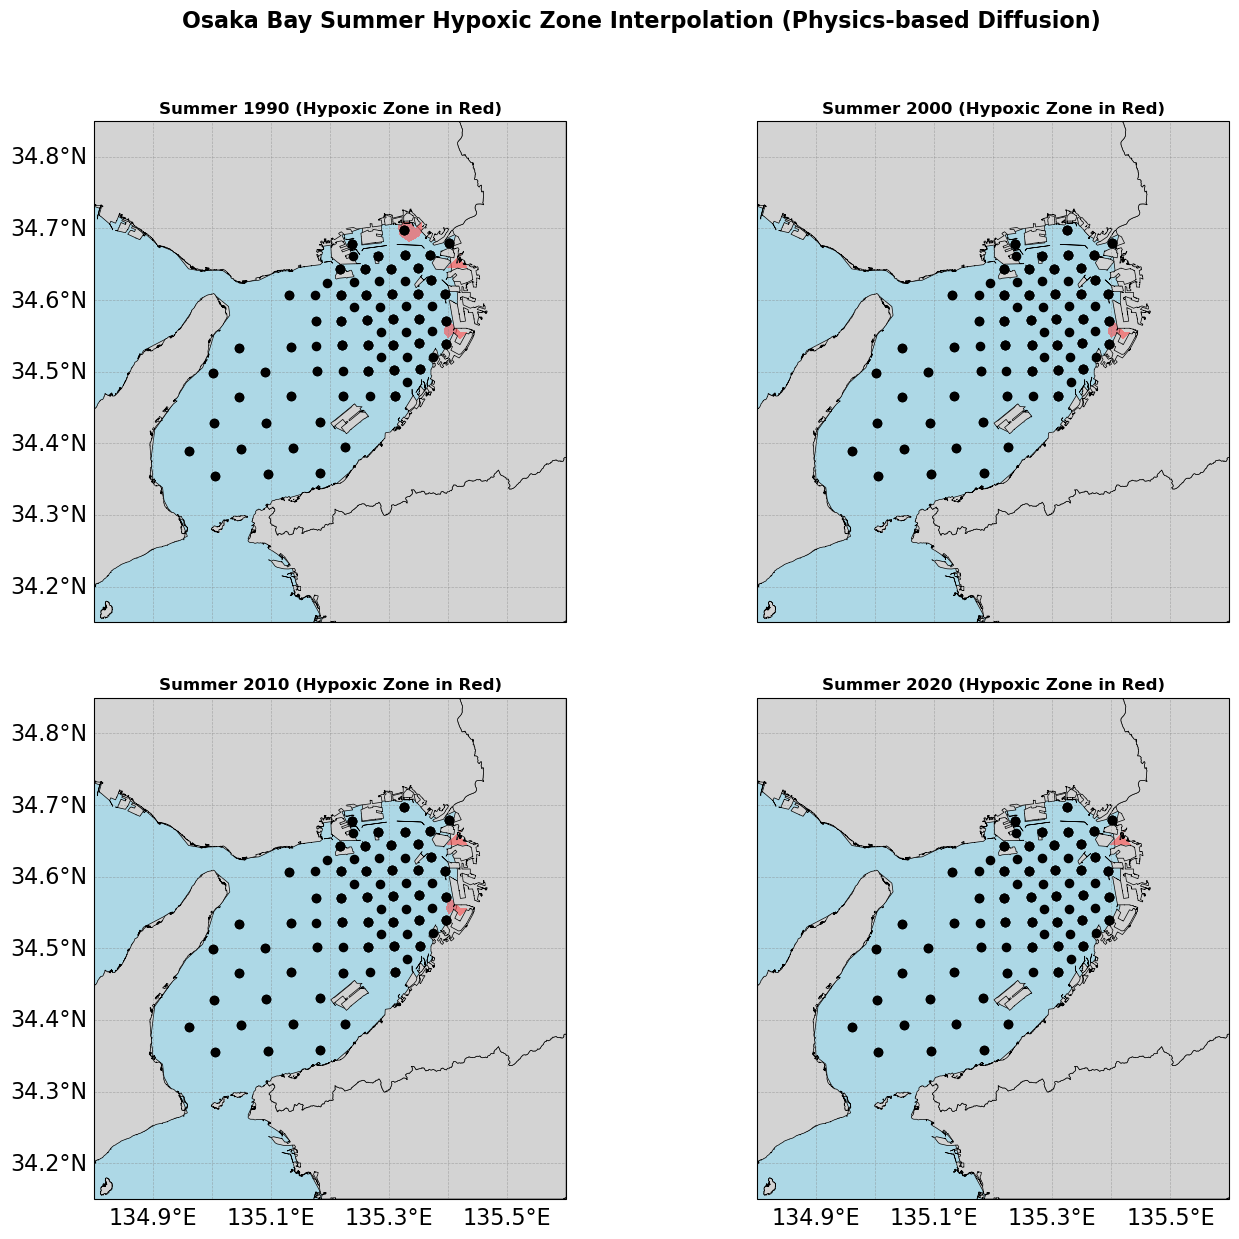

In [10]:
# Figure 1: Spatial Hypoxic Zone Interpolation Map (Examples)
land_boundary_file = MappingConfig.get_boundary_file("Seto Inland Sea")
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / land_boundary_file
sis_land_boundary = gpd.read_file(land_boundary_path)
if sis_land_boundary.crs != "EPSG:4326":
    sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

bbox = box(134.8, 34.15, 135.6, 34.85)
local_land = gpd.clip(sis_land_boundary, bbox)

# Choose 4 representative years to plot
plot_years = [y for y in [1990, 2000, 2010, 2020] if y in all_Z]
if len(plot_years) < 4:
    plot_years = [y for y in available_years if y in all_Z][:4]

fig, axes = plt.subplots(2, 2, figsize=(16, 14), subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

for i, y in enumerate(plot_years):
    ax = axes[i]
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    ax.set_extent([134.8, 135.6, 34.15, 34.85], crs=ccrs.PlateCarree())
    
    # Add Cartopy base features
    ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)
    
    Z = all_Z[y]
    # Plot filled contour where DO <= 2.0 mg/L (hypoxic)
    contour = ax.contourf(lon_wgs, lat_wgs, Z, levels=[0.0, 2.0], colors=['#ff4d4d'], alpha=0.6, transform=ccrs.PlateCarree(), zorder=0.8)
    
    # Plot high-res prefecture boundaries
    if not local_land.empty:
        local_land.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE, linewidth=MappingConfig.LINEWIDTH_LAND, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_LAND)
    
    # Plot biological survey stations
    ax.scatter(df_bio['lon_clean'], df_bio['lat_clean'], color='black', marker='o', s=35, label='Benthic Survey Stations', zorder=MappingConfig.ZORDER_OBSERVATIONS)
    
    # Gridlines
    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = (i % 2 == 0)
    gl.bottom_labels = (i >= 2)
    
    ax.set_title(f"Summer {y} (Hypoxic Zone in Red)", fontsize=12, fontweight='bold')

plt.subplots_adjust(wspace=0.15, hspace=0.15)
fig.suptitle("Osaka Bay Summer Hypoxic Zone Interpolation (Physics-based Diffusion)", fontsize=16, fontweight='bold', y=0.96)
plt.show()


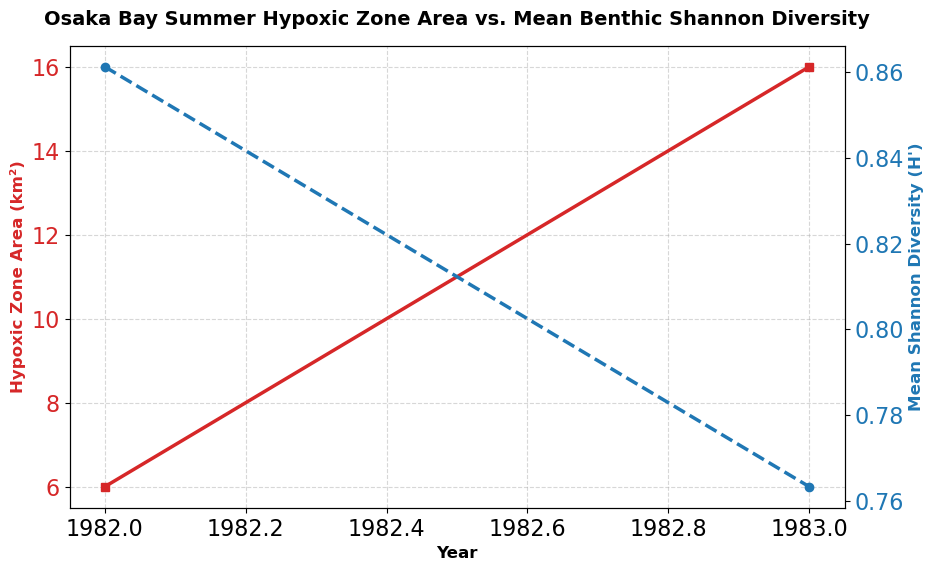

In [11]:
# Figure 2: Annual Hypoxic Area vs. Average Shannon Diversity
df_bio_yr = df_bio.groupby('Year')['shannon_index'].mean().reset_index()
df_merged_yr = pd.merge(df_hyp_areas, df_bio_yr, on='Year', how='inner')

fig, ax1 = plt.subplots(figsize=(10, 6))

color = '#d62728'
ax1.set_xlabel('Year', fontweight='bold', fontsize=12)
ax1.set_ylabel('Hypoxic Zone Area (km²)', color=color, fontweight='bold', fontsize=12)
ax1.plot(df_merged_yr['Year'], df_merged_yr['Hypoxic_Area_km2'], color=color, marker='s', linewidth=2.5, label='Hypoxic Area')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = '#1f77b4'
ax2.set_ylabel("Mean Shannon Diversity (H')", color=color, fontweight='bold', fontsize=12)
ax2.plot(df_merged_yr['Year'], df_merged_yr['shannon_index'], color=color, marker='o', linewidth=2.5, linestyle='--', label="Shannon H'")
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Osaka Bay Summer Hypoxic Zone Area vs. Mean Benthic Shannon Diversity', fontsize=14, fontweight='bold', pad=15)
plt.show()


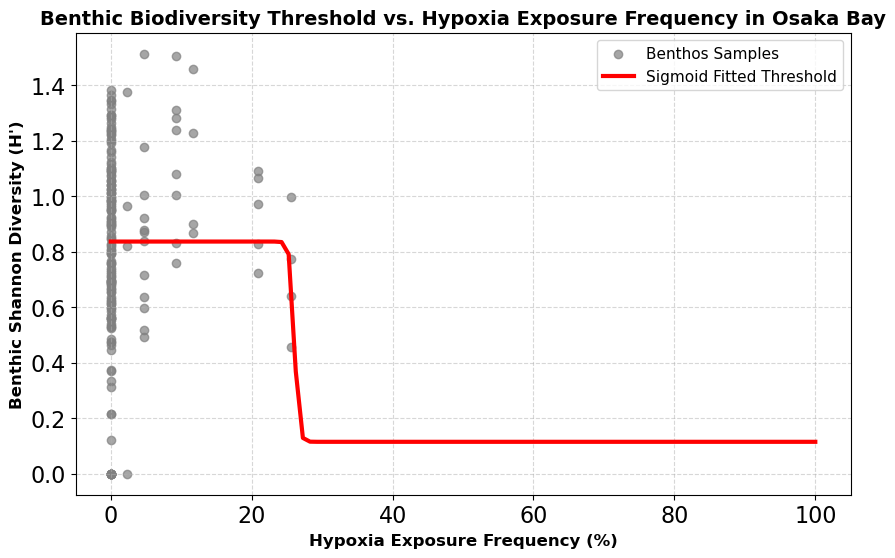

In [12]:
# Figure 3: Shannon Index vs. Hypoxia Exposure Frequency
plt.figure(figsize=(10, 6))
plt.scatter(x_data, y_data, color='gray', alpha=0.7, label='Benthos Samples')

if has_fit:
    x_fit = np.linspace(0, 100, 100)
    y_fit = sigmoid(x_fit, *popt)
    plt.plot(x_fit, y_fit, color='red', linewidth=3, label='Sigmoid Fitted Threshold')
else:
    p_coeff = np.polyfit(x_data, y_data, 2)
    x_fit = np.linspace(0, 100, 100)
    y_fit = np.polyval(p_coeff, x_fit)
    plt.plot(x_fit, y_fit, color='blue', linewidth=3, linestyle='--', label='Quadratic Fit Fallback')

plt.xlabel('Hypoxia Exposure Frequency (%)', fontsize=12, fontweight='bold')
plt.ylabel("Benthic Shannon Diversity (H')", fontsize=12, fontweight='bold')
plt.title('Benthic Biodiversity Threshold vs. Hypoxia Exposure Frequency in Osaka Bay', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


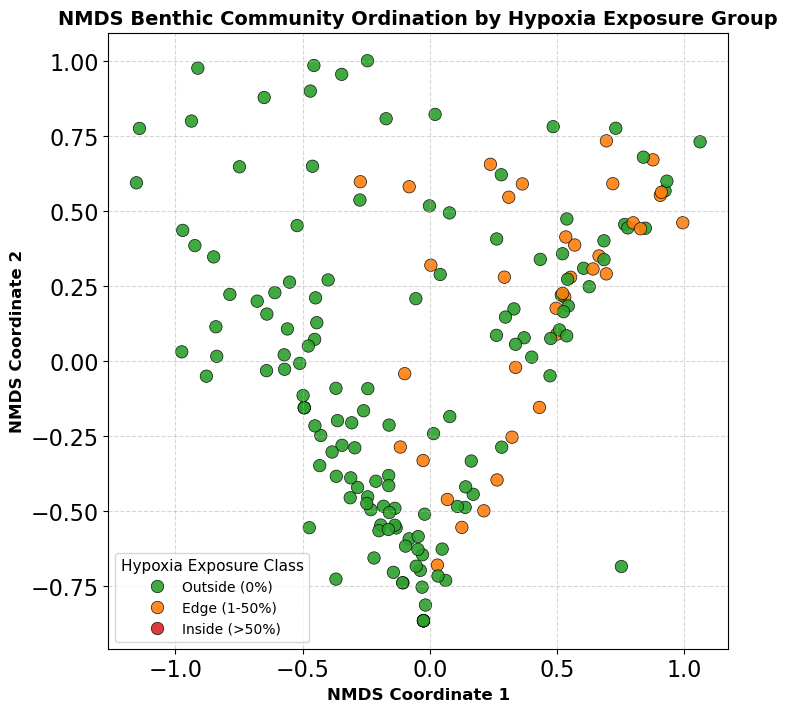

In [13]:
# Figure 4: NMDS Community Composition
plt.figure(figsize=(8, 8))
sns.scatterplot(
    x='NMDS1', y='NMDS2', hue='Exposure_Group',
    hue_order=['Outside (0%)', 'Edge (1-50%)', 'Inside (>50%)'],
    palette=['#2ca02c', '#ff7f0e', '#d62728'],
    s=80, data=df_bio_aligned, alpha=0.9, edgecolor='black', linewidth=0.5
)

plt.xlabel('NMDS Coordinate 1', fontsize=12, fontweight='bold')
plt.ylabel('NMDS Coordinate 2', fontsize=12, fontweight='bold')
plt.title('NMDS Benthic Community Ordination by Hypoxia Exposure Group', fontsize=14, fontweight='bold')
plt.legend(title='Hypoxia Exposure Class', title_fontsize=11, fontsize=10, loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


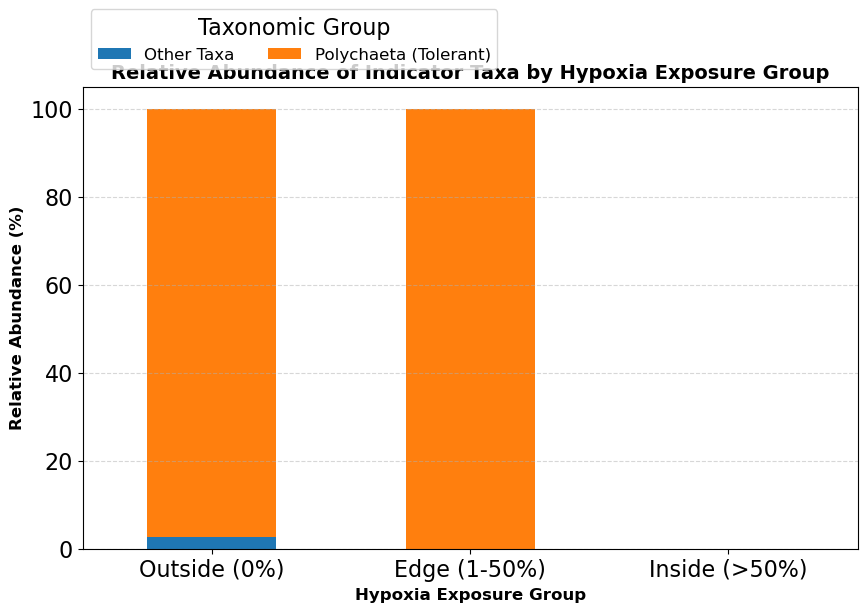

In [14]:
# Figure 5: Taxonomic Composition Stacked Bar Chart
def classify_taxon(name):
    name_upper = str(name).upper()
    if any(k in name_upper for k in ['スピオ', 'ゴカイ', 'LUMBRINERIS', 'PRIONOSPIO', 'EUCHONE', 'POLYCHAETA', '環形動物']):
        return 'Polychaeta (Tolerant)'
    elif any(k in name_upper for k in ['キサゴ', 'マテガイ', 'シズクガイ', 'モミジガイ', 'OPHIURA', 'BIVALVIA', 'ECHINODERMATA', '二枚貝', '棘皮動物']):
        return 'Mollusca/Echinodermata (Sensitive)'
    elif any(k in name_upper for k in ['ヨコエビ', 'クモガニ', 'CRUSTACEA', 'AMPHIPODA', '甲殻類']):
        return 'Crustaceans (Moderate)'
    else:
        return 'Other Taxa'

df_bio_long['Taxon_Group'] = df_bio_long['species'].apply(classify_taxon)
df_merged_tax = pd.merge(df_bio_long, df_bio_aligned[['Hypoxia_Exposure_Freq', 'Exposure_Group']], left_on='sample_id', right_index=True)

df_grouped_tax = df_merged_tax.groupby(['Exposure_Group', 'Taxon_Group'])['abundance'].sum().reset_index()
df_pivot_tax = df_grouped_tax.pivot(index='Exposure_Group', columns='Taxon_Group', values='abundance').fillna(0)
df_percentage_tax = df_pivot_tax.div(df_pivot_tax.sum(axis=1), axis=0) * 100.0
df_percentage_tax = df_percentage_tax.reindex(['Outside (0%)', 'Edge (1-50%)', 'Inside (>50%)'])

df_percentage_tax.plot(kind='bar', stacked=True, figsize=(10, 6), color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
plt.xlabel('Hypoxia Exposure Group', fontsize=12, fontweight='bold')
plt.ylabel('Relative Abundance (%)', fontsize=12, fontweight='bold')
plt.title('Relative Abundance of Indicator Taxa by Hypoxia Exposure Group', fontsize=14, fontweight='bold')
plt.xticks(rotation=0)
plt.legend(title='Taxonomic Group', loc='lower left', bbox_to_anchor=(0, 1.02), ncol=2, frameon=True)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.show()
